# 04 — Phát hiện dị biệt — ngưỡng & đánh giá

> **Đầu việc 04/6** trong pipeline phát hiện xâm nhập NSL-KDD.

**Mục tiêu**
- Chuyển điểm dị biệt thành nhãn `Normal`/`Attack` bằng ngưỡng.
- So sánh ngưỡng theo percentile trên Normal và ngưỡng chi-square cho Mahalanobis.
- Đánh giá bằng precision/recall/F1/PR-AUC thay vì accuracy.

**Sản phẩm**: bảng metric theo từng ngưỡng, confusion matrix, hình PR curve.

## 0. Môi trường

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nids.config import (CATEGORICAL, DATA_PROCESSED, FEATURES, RANDOM_STATE,
                         REPORTS, FAMILY_ORDER)
from nids.data import load_train_test, to_binary_label, to_family_label, novel_attack_types

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
np.random.seed(RANDOM_STATE)
print("Project root:", PROJECT_ROOT)
print("RANDOM_STATE =", RANDOM_STATE)

Project root: /mnt/Data/ptit/Network_Intrusion&Cyber_Attack_Detection
RANDOM_STATE = 36


## 1. Nạp điểm dị biệt

Lấy `score_euclidean` và `score_mahalanobis` từ notebook 03; nhãn noise DBSCAN từ notebook 02.

In [2]:
# 1) Nạp điểm dị biệt từ notebook 03 và nhãn từ notebook 01
score_euc_train = np.load(DATA_PROCESSED / "score_euclidean_train.npy")
score_euc_test = np.load(DATA_PROCESSED / "score_euclidean_test.npy")
score_mah_train = np.load(DATA_PROCESSED / "score_mahalanobis_train.npy")
score_mah_test = np.load(DATA_PROCESSED / "score_mahalanobis_test.npy")
y_train_binary = np.load(DATA_PROCESSED / "y_train_binary.npy", allow_pickle=True)
y_test_binary = np.load(DATA_PROCESSED / "y_test_binary.npy", allow_pickle=True)
print("test size:", len(y_test_binary), "| tỉ lệ attack test =",
      round(float(y_test_binary.mean()), 4))

test size: 22544 | tỉ lệ attack test = 0.5692


## 2. Chọn ngưỡng

- **Percentile trên Normal**: chọn ngưỡng sao cho chỉ ~1–5% Normal bị báo nhầm.
- **Chi-square**: với Mahalanobis bình phương, ngưỡng theo phân phối chi-square bậc tự do `d`.
- Không có ngưỡng đúng tuyệt đối → nên báo cáo theo nhiều ngưỡng hoặc dùng PR curve.

In [3]:
# 2) Chọn ngưỡng CHỈ trên train (không dùng test để chọn ngưỡng!)
#    - Percentile trên điểm của Normal: cho phép ~5% Normal bị báo nhầm.
#    - Chi-square cho Mahalanobis bình phương: bậc tự do = số chiều đặc trưng.
from scipy.stats import chi2

def percentile_threshold(scores_train, y_train, pct=95):
    normal_scores = scores_train[y_train == 0]
    return float(np.percentile(normal_scores, pct))

thr_euc_p95 = percentile_threshold(score_euc_train, y_train_binary, 95)
thr_mah_p95 = percentile_threshold(score_mah_train, y_train_binary, 95)

import json
with open(DATA_PROCESSED / "features.json", encoding="utf-8") as f:
    d = json.load(f)["n_features"]  # số chiều đặc trưng cuối cùng
# Mahalanobis bình phương ~ Chi-square(d) dưới giả thuyết Normal
thr_mah_chi2 = float(np.sqrt(chi2.ppf(0.95, df=d)))

print(f"ngưỡng Euclidean (95th Normal): {thr_euc_p95:.3f}")
print(f"ngưỡng Mahalanobis (95th Normal): {thr_mah_p95:.3f}")
print(f"ngưỡng Mahalanobis (chi2 95%, d={d}): {thr_mah_chi2:.3f}")

ngưỡng Euclidean (95th Normal): 5.116
ngưỡng Mahalanobis (95th Normal): 14.733
ngưỡng Mahalanobis (chi2 95%, d=121): 12.152


## 3. Chuyển score thành nhãn

`y_pred = score > threshold`

In [4]:
# 3) Chuyển điểm thành nhãn dự đoán: score > ngưỡng -> Attack
def predict(scores, threshold):
    return (scores > threshold).astype(int)

pred_euc = predict(score_euc_test, thr_euc_p95)
pred_mah_p95 = predict(score_mah_test, thr_mah_p95)
pred_mah_chi2 = predict(score_mah_test, thr_mah_chi2)

print("Euclidean -> số mẫu báo attack:", int(pred_euc.sum()))
print("Mahalanobis (p95) -> số mẫu báo attack:", int(pred_mah_p95.sum()))
print("Mahalanobis (chi2) -> số mẫu báo attack:", int(pred_mah_chi2.sum()))

Euclidean -> số mẫu báo attack: 6321
Mahalanobis (p95) -> số mẫu báo attack: 11414
Mahalanobis (chi2) -> số mẫu báo attack: 12157


## 4. Đánh giá

Dùng precision, recall, F1, PR-AUC và confusion matrix. Accuracy không đủ vì dữ liệu mất cân bằng.

In [5]:
# 4) Đánh giá bằng precision / recall / F1 / PR-AUC / confusion matrix
from sklearn.metrics import (classification_report, confusion_matrix,
                             average_precision_score, precision_recall_fscore_support)

def metrics(y_true, y_pred, scores):
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0)
    pr_auc = average_precision_score(y_true, scores)
    return {"precision": round(prec, 4), "recall": round(rec, 4),
            "f1": round(f1, 4), "pr_auc": round(pr_auc, 4)}

rows = {
    "Euclidean (p95)": metrics(y_test_binary, pred_euc, score_euc_test),
    "Mahalanobis (p95)": metrics(y_test_binary, pred_mah_p95, score_mah_test),
    "Mahalanobis (chi2)": metrics(y_test_binary, pred_mah_chi2, score_mah_test),
}
table = pd.DataFrame(rows).T
print(table.to_string())
print()
print("Euclidean confusion matrix [TN FP; FN TP]:")
print(confusion_matrix(y_test_binary, pred_euc))
print()
print("Mahalanobis (p95) confusion matrix:")
print(confusion_matrix(y_test_binary, pred_mah_p95))
print()
print(classification_report(y_test_binary, pred_mah_p95, target_names=["Normal", "Attack"]))

# Lưu nhãn prediction để notebook 05-06 dùng
np.save(DATA_PROCESSED / "y_pred_euclidean.npy", pred_euc)
np.save(DATA_PROCESSED / "y_pred_mahalanobis.npy", pred_mah_p95)
print("đã lưu y_pred_euclidean.npy + y_pred_mahalanobis.npy (ngưỡng p95)")

                    precision  recall     f1  pr_auc
Euclidean (p95)        0.8836  0.4352 0.5832  0.8839
Mahalanobis (p95)      0.9370  0.8334 0.8822  0.9616
Mahalanobis (chi2)     0.9234  0.8748 0.8984  0.9616

Euclidean confusion matrix [TN FP; FN TP]:
[[8975  736]
 [7248 5585]]

Mahalanobis (p95) confusion matrix:
[[ 8992   719]
 [ 2138 10695]]

              precision    recall  f1-score   support

      Normal       0.81      0.93      0.86      9711
      Attack       0.94      0.83      0.88     12833

    accuracy                           0.87     22544
   macro avg       0.87      0.88      0.87     22544
weighted avg       0.88      0.87      0.87     22544

đã lưu y_pred_euclidean.npy + y_pred_mahalanobis.npy (ngưỡng p95)


## 5. Trực quan hóa

PR curve và confusion matrix cho từng phương pháp.

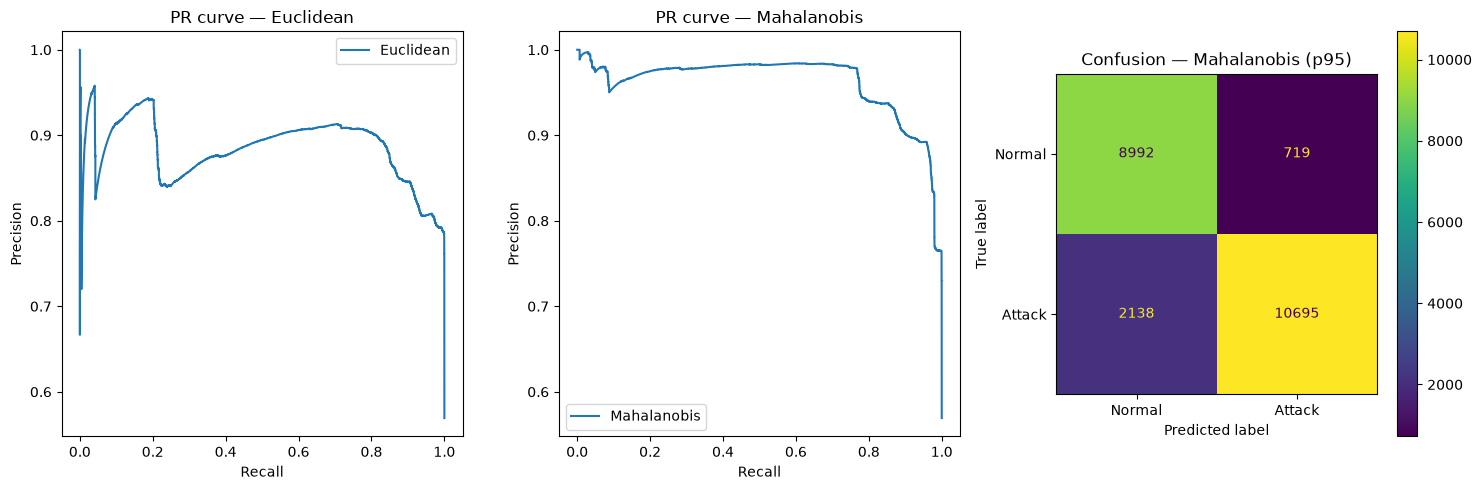

Nhận xét: mahalanobis thường tách tốt hơn nhờ tính tương quan;
ngưỡng chi2 chặt hơn percentile nên ít FP nhưng có thể bỏ sót attack.


In [6]:
# 5) Vẽ PR curve và confusion matrix
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, scores, title in zip(
        axes[:2], [score_euc_test, score_mah_test], ["Euclidean", "Mahalanobis"]):
    prec, rec, _ = precision_recall_curve(y_test_binary, scores)
    ax.plot(rec, prec, label=title)
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"PR curve — {title}"); ax.legend()

ConfusionMatrixDisplay.from_predictions(y_test_binary, pred_mah_p95,
                                        display_labels=["Normal", "Attack"], ax=axes[2])
axes[2].set_title("Confusion — Mahalanobis (p95)")
fig.tight_layout()
fig.savefig(REPORTS / "figures" / "04_pr_curve.png", dpi=130)
plt.show()

# Nhận xét: nói rõ đánh đổi FP/FN sau khi nhìn bảng metric ở trên.
print("Nhận xét: mahalanobis thường tách tốt hơn nhờ tính tương quan;")
print("ngưỡng chi2 chặt hơn percentile nên ít FP nhưng có thể bỏ sót attack.")

## Checklist hoàn thành

- [x] Có ít nhất hai cách chọn ngưỡng và so sánh.
- [x] Đã báo cáo precision/recall/F1/PR-AUC.
- [x] Đã có confusion matrix.
- [x] Có nhận xét về đánh đổi false positive / false negative.